# L1 -> L2

In [3]:
# Update the CRDS cache to the latest reference files
!crds sync --all

CRDS - INFO -  Syncing 243 files
CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_specpsf_0001.rmap      572 bytes  (1 / 243 files) (0 / 457.8 K bytes)
CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_skycells_0001.rmap      609 bytes  (2 / 243 files) (572 / 457.8 K bytes)
CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_sflat_0001.rmap      548 bytes  (3 / 243 files) (1.2 K / 457.8 K bytes)
CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_saturation_0003.rmap    2.4 K bytes  (4 / 243 files) (1.7 K / 457.8 K bytes)
CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_saturation_0002.rmap    2.4 K bytes  (5 / 243 files) (4.2 K / 457.8 K bytes)
CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_saturation_0001.rmap      635 bytes  (6 / 243 files) (6.6 K / 457.8 K bytes)
CRDS - INFO -  Fetching  /Users/dfadda/da

In [ ]:
from romancal.pipeline import ExposurePipeline as ELP
import os
import warnings
import logging
from glob import glob as gb
    
# Ignore warnings
warnings.filterwarnings('ignore')
# Ignore INFO
logging.getLogger().setLevel(logging.CRITICAL)

# Reduce uncal files
ufiles = gb('/Users/dfadda/Roman/FLO_Test/Orion/MAST_2026-10-09T1317/Roman/*_uncal.asdf')
steps = {'source_catalog':{'skip': True}}
for ufile in ufiles:
    res = ELP.call(ufile, steps=steps, save_results=True, update_version=True)

# Remove the wcs files
os.remove('*_wcs.asdf')

# Background files

In [3]:
from glob import glob as gb
import os
from flo.wfiskymatch import asdf2healpix
path = '/Users/dfadda/Roman/FLO_Test/Orion/'
outdir = path + 'Bkg/'
# Check if directory exists, otherwise creates it
os.makedirs(outdir, exist_ok=True)
files = sorted(gb(os.path.join(path,'*_cal.asdf')))
for file in files:
    asdf2healpix(file, outdir, savefits=False)  # NB: if True, background files are also saved as FITS files

file  r0108303005001001002_0002_wfi16_f213_cal  read in  0.600059986114502


Median bkg rms  0.83367777


/Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/astropy/nddata/blocks.py:160: RuntimeWarning: All-NaN slice encountered
  return func(reshaped, axis=axis)


saving in /Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001002_0002_wfi16_f213_cal.h5 time:  14.30814504623413
file  r0108303005001001002_0003_wfi16_f213_cal  read in  0.18857383728027344


Median bkg rms  0.6288354


...

/Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/astropy/nddata/blocks.py:160: RuntimeWarning: All-NaN slice encountered
  return func(reshaped, axis=axis)


saving in /Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001007_0001_wfi07_f213_cal.h5 time:  9.08730697631836
file  r0108303005001001007_0002_wfi07_f213_cal  read in  0.18435406684875488


Median bkg rms  0.2070513


/Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/astropy/nddata/blocks.py:160: RuntimeWarning: All-NaN slice encountered
  return func(reshaped, axis=axis)


saving in /Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001007_0002_wfi07_f213_cal.h5 time:  8.506839036941528


# Offsets computation

In [6]:
# Computing offsets
from flo.wfiskymatch import pixmatch
from glob import glob as gb
import os

path = '/Users/dfadda/Roman/FLO_Test/Orion/'
outdir = path + 'Bkg/'
files = sorted(gb(os.path.join(outdir,'*cal.h5')))

object = 'field'
offsets = pixmatch(files, outfile=outdir+object+'_offsets', offsets=None)

for file, offset in zip(files, offsets):
    print(file, offsets)

/Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001002_0002_wfi16_f213_cal.h5 [ 0.26221689  0.285437    1.6802329  -0.05858522 -0.97293327 -0.92099395]
/Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001002_0003_wfi16_f213_cal.h5 [ 0.26221689  0.285437    1.6802329  -0.05858522 -0.97293327 -0.92099395]
/Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001003_0002_wfi18_f213_cal.h5 [ 0.26221689  0.285437    1.6802329  -0.05858522 -0.97293327 -0.92099395]
/Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001006_0001_wfi09_f213_cal.h5 [ 0.26221689  0.285437    1.6802329  -0.05858522 -0.97293327 -0.92099395]
/Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001007_0001_wfi07_f213_cal.h5 [ 0.26221689  0.285437    1.6802329  -0.05858522 -0.97293327 -0.92099395]
/Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001007_0002_wfi07_f213_cal.h5 [ 0.26221689  0.285437    1.6802329  -0.05858522 -0.97293327 -0.92099395]


# Offset files

Adding computed offsets to original cal files

In [7]:
from flo.wfiskymatch import addOffset
import h5py
import os

path = '/Users/dfadda/Roman/FLO_Test/Orion/'
bkgpath = path + 'Bkg/'
h5file = bkgpath + 'field_offsets.h5'
with h5py.File(h5file, 'r') as hdf5_file:
    files = hdf5_file['files'][:]
    offsets = hdf5_file['offsets'][:]

# Create new files with added offsets
outdir = path + '/Offset/'
os.makedirs(outdir, exist_ok=True)
for file, offset in zip(files,offsets):
    print(file.decode(), offset)
    L2 = path + file.decode() +'.asdf'
    addOffset(L2, offset=offset, outdir = outdir)

r0108303005001001002_0002_wfi16_f213_cal 0.2622169
r0108303005001001002_0003_wfi16_f213_cal 0.285437
r0108303005001001003_0002_wfi18_f213_cal 1.6802329
r0108303005001001006_0001_wfi09_f213_cal -0.058585215
r0108303005001001007_0001_wfi07_f213_cal -0.9729333
r0108303005001001007_0002_wfi07_f213_cal -0.9209939


# Desaturate stars

## Obtaining the GAIA catalog

This passage requires the availability of the GAIA catalog for the field.
Once acquired and saved a catalog covering the entire area, this can be used for all the filters.

In [ ]:
# Get the list of coordinates at the time of the observation
from flo.simutils import gaiastars
import roman_datamodels as rdm

# Use a central image to get the position or just write the position of the survey center
with rdm.open('Offset/r0108303005001001002_0002_wfi16_f213_off_cal.asdf') as dm:
    astro = dm.meta.wcs
    ra0, dec0 = astro(2044.5,2044.5)
    start_time = dm.meta.exposure.start_time

# Radius of the catalog in degrees
radius = 0.5  

# Retrieve catalog and save it locally
gaia_catalog = gaiastars(ra=ra0, dec=dec0, radius=radius, star=0.5, maglim=16, obs_time=start_time)
gaia_catalog.write('gaia_catalog.ecsv', format='ascii.ecsv', overwrite=True)

## Desaturate the stars in the survey

In [1]:
# Desaturate the PSFs
from flo.desaturate import desaturatePsf
from astropy.coordinates import SkyCoord
from astropy.table import Table
from glob import glob as gb
import os

path = '/Users/dfadda/Roman/FLO_Test/Orion/Offset/'
ufiles = gb(path + 'r*_off_cal.asdf')

gaia_catalog = Table.read('/Users/dfadda/Roman/FLO_Test/Orion/gaia_catalog.ecsv')
stars = SkyCoord(gaia_catalog['ra'].value, gaia_catalog['dec'].value, unit='deg', frame = 'icrs')

for L2 in ufiles:
    desaturatePsf(L2, stars)
    # Remove the offset file
    os.remove(L2)

There are 167 bright stars which will be corrected
PSF substitution for 101 non GAIA saturated sources 
Corrected a total of 268 saturated sources
There are 45 bright stars which will be corrected
PSF substitution for 58 non GAIA saturated sources 
Corrected a total of 103 saturated sources
There are 84 bright stars which will be corrected
PSF substitution for 51 non GAIA saturated sources 
Corrected a total of 135 saturated sources
There are 154 bright stars which will be corrected
PSF substitution for 83 non GAIA saturated sources 
Corrected a total of 237 saturated sources
There are 61 bright stars which will be corrected
PSF substitution for 20 non GAIA saturated sources 
Corrected a total of 81 saturated sources
There are 104 bright stars which will be corrected
PSF substitution for 38 non GAIA saturated sources 
Corrected a total of 142 saturated sources


# Masking of bad pixels

Here we should also include possible masking of regions affected by artefacts.
Updated masks will be generated asap.

In [2]:
from glob import glob as gb
from flo.badpixels import maskNegativePixels as maskNP
import numpy as np
import os 

path = '/Users/dfadda/Roman/FLO_Test/Orion/Offset/'
ufiles = gb(path + 'r*_off_cal_us.asdf')

for ufile in ufiles:
    maskNP(ufile)
    os.remove(ufile)

/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001003_0002_wfi18_f213_off_cal_us.asdf: 0.01% negative non-masked pixels, median 11.2
/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0002_wfi07_f213_off_cal_us.asdf: 0.08% negative non-masked pixels, median 5.4
/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001006_0001_wfi09_f213_off_cal_us.asdf: 0.02% negative non-masked pixels, median 9.5
/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001002_0002_wfi16_f213_off_cal_us.asdf: 0.02% negative non-masked pixels, median 18.8
/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001002_0003_wfi16_f213_off_cal_us.asdf: 0.02% negative non-masked pixels, median 16.4
/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0001_wfi07_f213_off_cal_us.asdf: 0.08% negative non-masked pixels, median 4.6


# Mosaic

There are two ways to obtain a mosaic:

1. direct, using all the images at once

2. tiled, creating tiles and then stitching them together

## Direct way

### Create the association file

In [9]:
# Association file
import romancal.associations.asn_from_list as asn_from_list
from glob import glob as gb

path = '/Users/dfadda/Roman/FLO_Test/Orion/Offset/'
input_files = gb(path + 'r*_ok.asdf')
product_name = 'Orion_f213'

# Create the ASN JSON object
asn = asn_from_list.asn_from_list([(i, 'science') for i in input_files], 
                                  product_name=product_name, 
                                  with_exptype=True, target='')

# Write the ASN file to disk
_, serialized = asn.dump()
with open(path+'Orion_f213_asn.json', 'w') as f:
    f.write(serialized)

### Coadd the images

In [10]:
# Mosaic without computing new offsets
from romancal.pipeline import MosaicPipeline

path = '/Users/dfadda/Roman/FLO_Test/Orion/Offset/'

steps = {'outlier_detection':{'skip':True},
         'skymatch':{'skip':True},
         'resample':{'resample_on_skycell':False},
         'source_catalog':{'skip':True},
        }

result = MosaicPipeline.call(path+'Orion_f213_asn.json', 
                             save_results=True, resample_on_skycell=False,
                             steps=steps)

2026-10-23 12:46:25,515 - romancal.associations._association - WARNING - Cannot validate: <class 'romancal.associations._association._Association'> has no schema. Presuming OK.
2026-10-23 12:46:25,577 - CRDS - ERROR -  Error determining best reference for 'pars-mosaicpipeline'  =   Unknown reference type 'pars-mosaicpipeline'
2026-10-23 12:46:25,580 - stpipe.step - INFO - MosaicPipeline instance created.
2026-10-23 12:46:25,581 - stpipe.step - INFO - FluxStep instance created.
2026-10-23 12:46:25,581 - stpipe.step - INFO - SkyMatchStep instance created.
2026-10-23 12:46:25,582 - stpipe.step - INFO - OutlierDetectionStep instance created.
2026-10-23 12:46:25,582 - stpipe.step - INFO - ResampleStep instance created.
2026-10-23 12:46:25,583 - stpipe.step - INFO - SourceCatalogStep instance created.
2026-10-23 12:46:25,681 - stpipe.step - INFO - Step MosaicPipeline running with args ('/Users/dfadda/Roman/FLO_Test/Orion/Offset/Orion_f213_asn.json',).
2026-10-23 12:46:25,685 - stpipe.step - 

### Display the result

Pixel scale  1.0  pixels
Pixel scale from wcs  [0.10876549 0.10876549]  arcsec
size of skycell:  (9480, 7804)


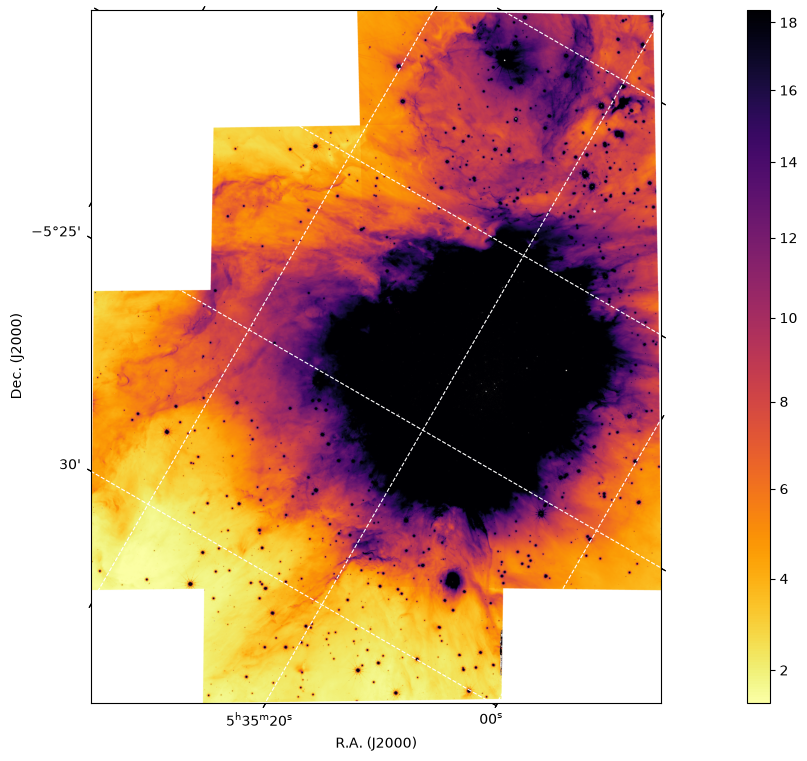

In [11]:
# Display mosaic
import matplotlib.pyplot as plt
import roman_datamodels as rdm
from astropy import visualization
from astropy.table import Table
import numpy as np
from astropy.wcs.utils import proj_plane_pixel_scales as ppps

filename = 'Orion_f213_coadd.asdf'

with rdm.open(filename) as dm:
    wcs = dm.meta.wcs
    meta = dm.meta
    data = dm.data.copy()
    hdr = dm.meta.wcs.to_fits()[0]
    print('Pixel scale ', dm.meta.resample['pixel_scale_ratio'],' pixels')

from astropy.wcs import WCS
wcs = WCS(hdr)
print('Pixel scale from wcs ', ppps(wcs)*3600, ' arcsec')
print('size of skycell: ', np.shape(data))

norm = visualization.ImageNormalize(data,
                                    interval=visualization.ZScaleInterval(contrast=1),
                                    stretch=visualization.AsinhStretch(a=1))

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={'projection':wcs})

plot = ax.imshow(data, norm=norm, origin='lower',cmap='inferno_r')
ax.coords.grid(True, color='white', ls='dashed')
ax.coords[0].set_axislabel('R.A. (J2000)')
ax.coords[1].set_axislabel('Dec. (J2000)')

cax = plt.axes([0.925, 0.11, 0.025,0.77 ])
plt.colorbar(mappable=plot, cax=cax)

plt.show()

### Save as a FITS file

In [12]:
# Original mosaic to FITS
import roman_datamodels as rdm
from astropy.io import fits

filename = 'Orion_f213_coadd.asdf'

with rdm.open(filename) as dm:
    data = dm.data.copy()
    hdr = dm.meta.wcs.to_fits()[0]

fits.writeto('Orion_f213_coadd.fits', data, hdr, overwrite=True)

## Via tiling

Before running the mosaicker, one has to change the vparity in romancal.

In your romancal repository, open the file:
```
romancal/skycell/skymap.py 
```
and change the line after:
```
matrix = wcsinfo.get("rotation_matrix", None)
```
to: 
```
vparity=-1,
```
The next version of romancal will have vparity=-1 by default.

### Create the association files

In [13]:
from flo.mosaic import make_cells_asn
from glob import glob as gb
import os

path = '/Users/dfadda/Roman/FLO_Test/Orion/Offset/'
files = gb(path + 'r*_ok.asdf')
refdir = os.environ.get('CRDS_PATH')+'references/roman/wfi/'
outname = 'tile'
make_cells_asn(files, outname=outname, refdir=refdir)

Median orientation is 149.86300131473536 degrees
orientation  149.86300131473536
0 0 ['/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0001_wfi07_f213_off_cal_us_ok.asdf', '/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0002_wfi07_f213_off_cal_us_ok.asdf']
0 1 ['/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0001_wfi07_f213_off_cal_us_ok.asdf', '/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0002_wfi07_f213_off_cal_us_ok.asdf', '/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001006_0001_wfi09_f213_off_cal_us_ok.asdf']
1 0 ['/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0001_wfi07_f213_off_cal_us_ok.asdf', '/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001002_0002_wfi16_f213_off_cal_us_ok.asdf', '/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0002_wfi07_f213_off_cal_us_ok.asdf']
1 1 ['/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0001_wfi07_f213_off_cal_us_

### Obtain the tiles

In [2]:
# Tiles 
from glob import glob as gb
from romancal.pipeline import MosaicPipeline

path = '/Users/dfadda/Roman/FLO_Test/Orion/'
outname = 'tile'
asnfiles = gb(outname+'*.asn')

steps = {'outlier_detection':{'skip':True},
         'skymatch':{'skip':True},
         'resample':{'resample_on_skycell':True},
         'source_catalog':{'skip':True},
        }

for asnfile in asnfiles:
    print('asnfile is: ', asnfile)
    result = MosaicPipeline.call(asnfile, 
                                 save_results=True, resample_on_skycell=True,
                                 steps=steps)

2026-10-23 12:50:37,177 - romancal.associations._association - WARNING - Cannot validate: <class 'romancal.associations._association._Association'> has no schema. Presuming OK.


asnfile is:  tile_084p05x00y00.asn


2026-10-23 12:50:37,648 - CRDS - ERROR -  Error determining best reference for 'pars-mosaicpipeline'  =   Unknown reference type 'pars-mosaicpipeline'
2026-10-23 12:50:37,650 - stpipe.step - INFO - MosaicPipeline instance created.
2026-10-23 12:50:37,650 - stpipe.step - INFO - FluxStep instance created.
2026-10-23 12:50:37,651 - stpipe.step - INFO - SkyMatchStep instance created.
2026-10-23 12:50:37,652 - stpipe.step - INFO - OutlierDetectionStep instance created.
2026-10-23 12:50:37,652 - stpipe.step - INFO - ResampleStep instance created.
2026-10-23 12:50:37,653 - stpipe.step - INFO - SourceCatalogStep instance created.
2026-10-23 12:50:37,712 - stpipe.step - INFO - Step MosaicPipeline running with args ('tile_084p05x00y00.asn',).
2026-10-23 12:50:37,716 - stpipe.step - INFO - Step MosaicPipeline parameters are:
  pre_hooks: []
  post_hooks: []
  output_file: None
  output_dir: None
  output_ext: .asdf
  output_use_model: False
  output_use_index: True
  save_results: True
  skip: Fa

asnfile is:  tile_084p05x00y01.asn


2026-10-23 12:50:42,618 - stpipe.step - INFO - Step flux running with args (<romancal.datamodels.library.ModelLibrary object at 0x169ea2c40>,).
2026-10-23 12:50:42,812 - py.warnings - WARNING - /Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/asdf/tags/core/ndarray.py:440: RuntimeWarning: overflow encountered in multiply
  return getattr(self._make_array(), name)(*args)

2026-10-23 12:50:43,783 - stpipe.step - INFO - Step flux done
2026-10-23 12:50:43,839 - stpipe.step - INFO - Step skymatch running with args (<romancal.datamodels.library.ModelLibrary object at 0x169ea2c40>,).
2026-10-23 12:50:43,840 - stpipe.step - INFO - Step skipped.
2026-10-23 12:50:44,430 - stpipe.step - INFO - Step outlier_detection running with args (<romancal.datamodels.library.ModelLibrary object at 0x169ea2c40>,).
2026-10-23 12:50:44,431 - stpipe.step - INFO - Step skipped.
2026-10-23 12:50:45,021 - stpipe.step - INFO - Step resample running with args (<romancal.datamodels.library.ModelLibrary o

...

2026-10-23 12:51:04,380 - stpipe.step - INFO - Step flux running with args (<romancal.datamodels.library.ModelLibrary object at 0x16d7b58b0>,).
2026-10-23 12:51:04,767 - py.warnings - WARNING - /Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/asdf/tags/core/ndarray.py:440: RuntimeWarning: overflow encountered in multiply
  return getattr(self._make_array(), name)(*args)

2026-10-23 12:51:05,618 - stpipe.step - INFO - Step flux done
2026-10-23 12:51:05,679 - stpipe.step - INFO - Step skymatch running with args (<romancal.datamodels.library.ModelLibrary object at 0x16d7b58b0>,).
2026-10-23 12:51:05,679 - stpipe.step - INFO - Step skipped.
2026-10-23 12:51:06,348 - stpipe.step - INFO - Step outlier_detection running with args (<romancal.datamodels.library.ModelLibrary object at 0x16d7b58b0>,).
2026-10-23 12:51:06,348 - stpipe.step - INFO - Step skipped.
2026-10-23 12:51:07,013 - stpipe.step - INFO - Step resample running with args (<romancal.datamodels.library.ModelLibrary o

asnfile is:  tile_084p05x01y01.asn


2026-10-23 12:51:14,796 - stpipe.step - INFO - Step flux running with args (<romancal.datamodels.library.ModelLibrary object at 0x15a78aeb0>,).
2026-10-23 12:51:14,997 - py.warnings - WARNING - /Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/asdf/tags/core/ndarray.py:440: RuntimeWarning: overflow encountered in multiply
  return getattr(self._make_array(), name)(*args)

2026-10-23 12:51:17,246 - stpipe.step - INFO - Step flux done
2026-10-23 12:51:17,316 - stpipe.step - INFO - Step skymatch running with args (<romancal.datamodels.library.ModelLibrary object at 0x15a78aeb0>,).
2026-10-23 12:51:17,317 - stpipe.step - INFO - Step skipped.
2026-10-23 12:51:18,543 - stpipe.step - INFO - Step outlier_detection running with args (<romancal.datamodels.library.ModelLibrary object at 0x15a78aeb0>,).
2026-10-23 12:51:18,543 - stpipe.step - INFO - Step skipped.
2026-10-23 12:51:19,769 - stpipe.step - INFO - Step resample running with args (<romancal.datamodels.library.ModelLibrary o

asnfile is:  tile_084p05x01y00.asn


2026-10-23 12:51:49,617 - stpipe.step - INFO - Step flux running with args (<romancal.datamodels.library.ModelLibrary object at 0x16b66e5d0>,).
2026-10-23 12:51:49,813 - py.warnings - WARNING - /Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/asdf/tags/core/ndarray.py:440: RuntimeWarning: overflow encountered in multiply
  return getattr(self._make_array(), name)(*args)

2026-10-23 12:51:50,794 - stpipe.step - INFO - Step flux done
2026-10-23 12:51:50,858 - stpipe.step - INFO - Step skymatch running with args (<romancal.datamodels.library.ModelLibrary object at 0x16b66e5d0>,).
2026-10-23 12:51:50,858 - stpipe.step - INFO - Step skipped.
2026-10-23 12:51:51,478 - stpipe.step - INFO - Step outlier_detection running with args (<romancal.datamodels.library.ModelLibrary object at 0x16b66e5d0>,).
2026-10-23 12:51:51,479 - stpipe.step - INFO - Step skipped.
2026-10-23 12:51:52,099 - stpipe.step - INFO - Step resample running with args (<romancal.datamodels.library.ModelLibrary o

### Stitch the tiles

In [4]:
from glob import glob as gb
from flo.mosaic import stitchCells
import os

outname = 'tile'
asdffiles = gb(outname+'*.asdf')
stitchCells(asdffiles, outname='Orion_tiles')

# remove the tiles
for asdffile in asdffiles:
    os.remove(asdffile)

Rotation angle is:  -30.13699913021141
Scale is:  3.0212636096634107e-05


### Display the mosaic with tiles

SIMPLE True
BITPIX -64
NAXIS 2
NAXIS1 7805
NAXIS2 9477
WCSAXES 2
WCSNAME world
CRPIX1 4171.0
CRPIX2 4630.0
CRVAL1 83.85694409959488
CRVAL2 -5.398694251584093
PC1_1 -2.6128715109216e-05
PC1_2 1.5168837353239e-05
PC2_1 1.5168837353239e-05
PC2_2 2.61287151092168e-05
CDELT1 1.0
CDELT2 1.0
CTYPE1 RA---TAN
CTYPE2 DEC--TAN
CUNIT1 deg
CUNIT2 deg
LONPOLE 180
LATPOLE -5.398694251584093
RADESYS ICRS
MJDREF 0.0
WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN'
CUNIT : 'deg' 'deg'
CRVAL : 83.85694409959488 -5.398694251584093
CRPIX : 4171.0 4630.0
PC1_1 PC1_2  : -2.6128715109216e-05 1.5168837353239e-05
PC2_1 PC2_2  : 1.5168837353239e-05 2.61287151092168e-05
CDELT : 1.0 1.0
NAXIS : 7805  9477
Pixel scale from wcs  [0.10876549 0.10876549]  arcsec
size of image:  (9477, 7805)
084p05x00y00 83.91200639367968 -5.605178547753301
084p05x00y01 83.98818596730983 -5.474524118261443
084p05x00y02 84.06433224893658 -5.343860073935448
084p05x01y00 83.7807456034122 -5.529332741880521
084p05x01y01 83

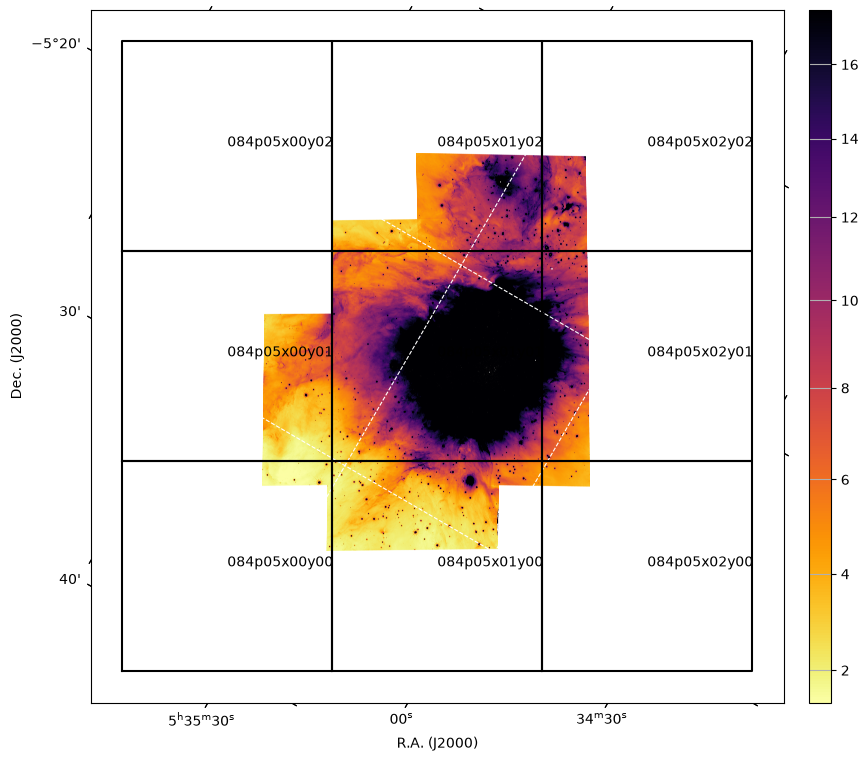

In [5]:
# Display mosaic
import matplotlib.pyplot as plt
import roman_datamodels as rdm
from astropy import visualization
from astropy.table import Table
import numpy as np
from astropy.wcs.utils import proj_plane_pixel_scales as ppps
from astropy.wcs import WCS
from astropy.io import fits

with fits.open('Orion_tiles.fits') as f:
    image = f[0].data
    header = f[0].header

wcs = WCS(header)

for k in header.keys():
    print(k, header[k])

print(wcs)

#wcs = WCS(hdr)
print('Pixel scale from wcs ', ppps(wcs)*3600, ' arcsec')
print('size of image: ', np.shape(image))


norm = visualization.ImageNormalize(image,
                                    interval=visualization.ZScaleInterval(contrast=1),
                                    stretch=visualization.AsinhStretch(a=1))

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={'projection':wcs})

plot = ax.imshow(image, norm=norm,  origin='lower',cmap='inferno_r')
ax.coords.grid(True, color='white', ls='dashed')
ax.coords[0].set_axislabel('R.A. (J2000)')
ax.coords[1].set_axislabel('Dec. (J2000)')

skyref = '/Users/dfadda/data/crds_cache/references/roman/wfi/roman_wfi_skycells_0001.asdf'
with rdm.open(skyref) as dm:
    tiles = dm.projection_regions.copy()
    skycells = dm.skycells.copy()
for skycell in skycells:
    rac = [skycell['ra_corn1'],skycell['ra_corn2'],skycell['ra_corn3'],skycell['ra_corn4'],skycell['ra_corn1']]
    dec = [skycell['dec_corn1'],skycell['dec_corn2'],skycell['dec_corn3'],skycell['dec_corn4'],skycell['dec_corn1']]
    plt.plot(rac, dec,color='black',transform=ax.get_transform('icrs'))
    plt.text(skycell['ra_center'], skycell['dec_center'], skycell['name'],transform=ax.get_transform('icrs'))
    print(skycell['name'],skycell['ra_center'], skycell['dec_center'])

cax = plt.axes([0.925, 0.11, 0.025,0.77 ])
plt.colorbar(mappable=plot, cax=cax)
plt.grid()
plt.show()